
# Gaussian Mixtures — Set Transformer Experiments

## Objective

This experiment compares five neural network architectures on a Gaussian mixture dataset to evaluate their ability to learn from unordered sets of points.

The models evaluated are:

- Standard Transformer
- Set Transformer (ISAB + PMA + SAB)
- ISAB + PMA
- SAB + PMA
- MLP Baseline

The task is to predict the number of distinct clusters represented in a set of 100 two-dimensional points.

The experiment investigates how different attention mechanisms and permutation-invariant architectures affect classification accuracy, training behavior, and generalization.


In [8]:
import os

os.chdir("/work/classes/ai4200-001-2026f/jfinnegan42/Set-Transformer")

print("Current directory:", os.getcwd())
print("Results folder exists:", os.path.exists("results"))

Current directory: /work/classes/ai4200-001-2026f/jfinnegan42/Set-Transformer
Results folder exists: True



## Model Training

All five models were trained using the same experimental configuration to provide a consistent comparison.

### Training Configuration

- **Dataset:** Gaussian Mixtures
- **Training samples:** 9,000
- **Validation samples:** 1,000
- **Test samples:** 2,000
- **Points per set:** 100
- **Features per point:** 2 (x and y coordinates)
- **Epochs:** 20
- **Batch size:** 32
- **Optimizer:** AdamW
- **Learning rate:** 0.0003
- **Weight decay:** 0.0001
- **Loss function:** Cross-entropy
- **Random seed:** 42

The models were evaluated using classification accuracy and cross-entropy loss. The checkpoint with the lowest validation loss was selected for final testing.


In [11]:
models = ["standard", "set", "isab", "sab", "baseline"]

for model in models:
    print(f"\nTraining {model.upper()}...", flush=True)

    command = [
        sys.executable, "-u", "train.py",
        "--dataset", "gaussian",
        "--model", model,
        "--epochs", "20",
        "--batch-size", "32"
    ]

    result = subprocess.run(command, env=env)

    if result.returncode != 0:
        print(f"FAILED: {model}")
        break

print("\nGaussian experiments finished!")


Training STANDARD...
Device: cuda
Training fraction: 100%
Training examples: 9000
Validation examples: 1000
Test examples: 2000

STANDARD / GAUSSIAN / 397,444 parameters
Epoch 01/20 | train loss 0.8835 | val loss 0.6841 | val accuracy 0.6780
Epoch 02/20 | train loss 0.6788 | val loss 0.7009 | val accuracy 0.6800
Epoch 03/20 | train loss 0.6334 | val loss 0.6522 | val accuracy 0.7190
Epoch 04/20 | train loss 0.6039 | val loss 0.5748 | val accuracy 0.7530
Epoch 05/20 | train loss 0.5867 | val loss 0.5794 | val accuracy 0.7290
Epoch 06/20 | train loss 0.5847 | val loss 0.5842 | val accuracy 0.7340
Epoch 07/20 | train loss 0.5717 | val loss 0.5740 | val accuracy 0.7460
Epoch 08/20 | train loss 0.5553 | val loss 0.5912 | val accuracy 0.7380
Epoch 09/20 | train loss 0.5432 | val loss 0.5528 | val accuracy 0.7420
Epoch 10/20 | train loss 0.5380 | val loss 0.5782 | val accuracy 0.7510
Epoch 11/20 | train loss 0.5204 | val loss 0.5266 | val accuracy 0.7590
Epoch 12/20 | train loss 0.5175 | val


## Validation Loss Comparison

This experiment compares how well the five models generalize to unseen validation data over 20 training epochs.

The Standard Transformer, Set Transformer, ISAB, and SAB models all show decreasing validation loss, eventually stabilizing around 0.5.

The MLP baseline behaves differently. Its validation loss initially decreases but then increases dramatically, reaching approximately 2.84 by epoch 20.

This indicates severe overfitting: the MLP learns the training data but fails to generalize effectively to unseen examples.

The attention-based architectures demonstrate substantially better generalization on this dataset.


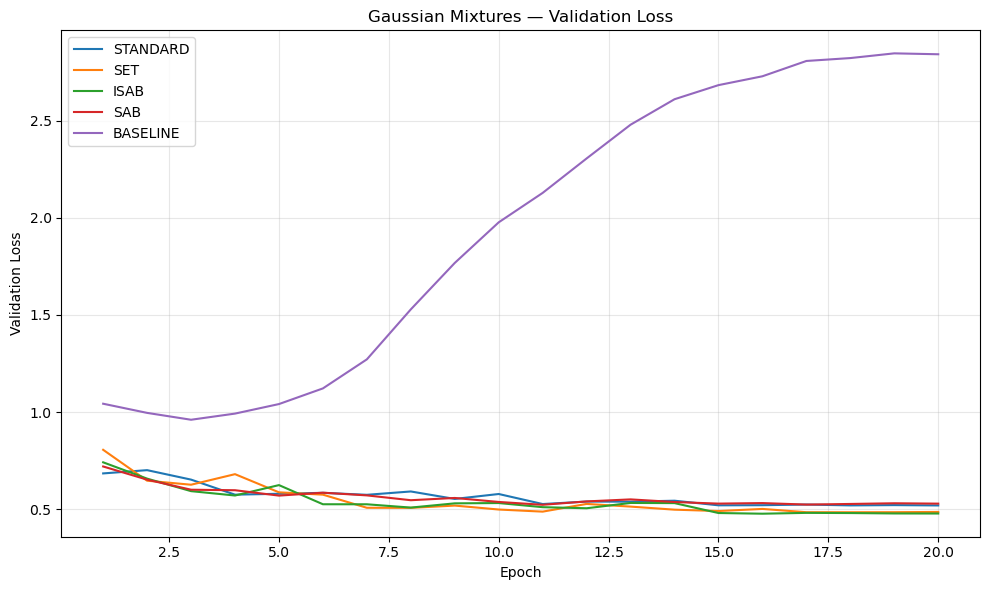

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

models = ["standard", "set", "isab", "sab", "baseline"]

plt.figure(figsize=(10, 6))

for model in models:
    df = pd.read_csv(
        f"results/gaussian_{model}_fraction_100_history.csv"
    )
    plt.plot(
        df["epoch"],
        df["val_loss"],
        label=model.upper()
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Gaussian Mixtures — Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("results/gaussian_validation_loss.png", dpi=300)
plt.show()


## Training Loss Comparison

This graph shows how the training loss changes over 20 epochs for all five models.

All five models successfully reduce their training loss, indicating that they are learning patterns from the training data.

The MLP baseline achieves the lowest training loss, approaching zero by epoch 20. However, its validation loss increases substantially during the same period.

This demonstrates that low training loss does not necessarily indicate good generalization. The MLP is memorizing patterns in the training data rather than learning representations that transfer effectively to unseen examples.

The four attention-based models maintain higher training losses but achieve significantly better validation performance, demonstrating the importance of architecture and permutation invariance when processing unordered sets.


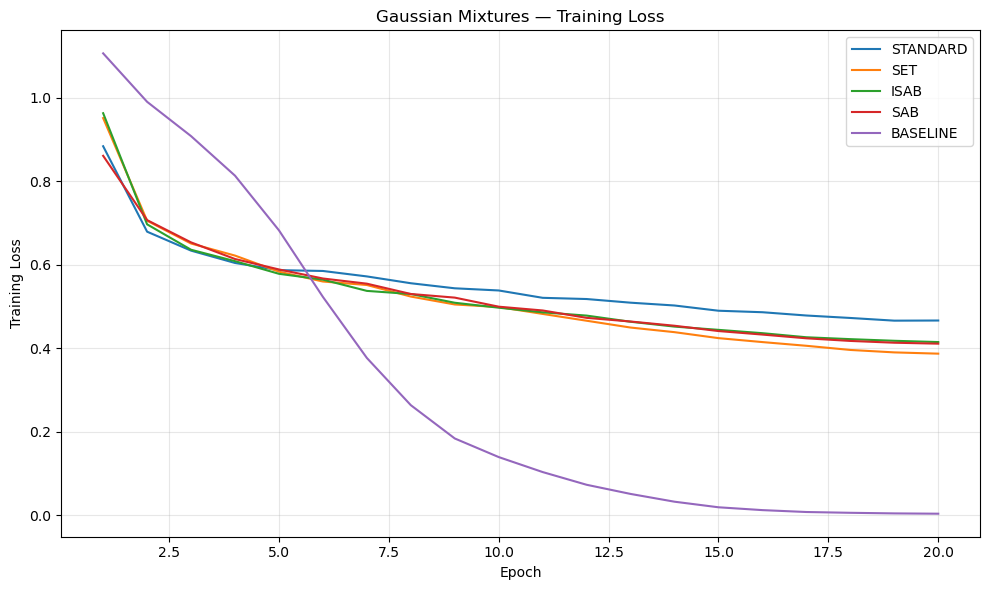

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

models = ["standard", "set", "isab", "sab", "baseline"]

plt.figure(figsize=(10, 6))

for model in models:
    df = pd.read_csv(
        f"results/gaussian_{model}_fraction_100_history.csv"
    )
    plt.plot(df["epoch"], df["train_loss"], label=model.upper())

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Gaussian Mixtures — Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("results/gaussian_training_loss.png", dpi=300)
plt.show()


## Final Test Accuracy

This graph compares the classification accuracy of all five models on the held-out Gaussian Mixtures test set.

| Model | Test Accuracy |
|---|---:|
| Standard Transformer | 76.70% |
| Full Set Transformer | 78.75% |
| ISAB + PMA | 77.75% |
| SAB + PMA | 75.55% |
| MLP Baseline | 54.20% |

The Full Set Transformer achieved the highest test accuracy at 78.75%, outperforming the Standard Transformer by 2.05 percentage points and the MLP baseline by 24.55 percentage points.

ISAB + PMA performed nearly as well as the Full Set Transformer, suggesting that the reduced architecture can achieve competitive performance with fewer parameters.

Overall, the attention-based models substantially outperformed the MLP baseline on this unordered-set classification task.


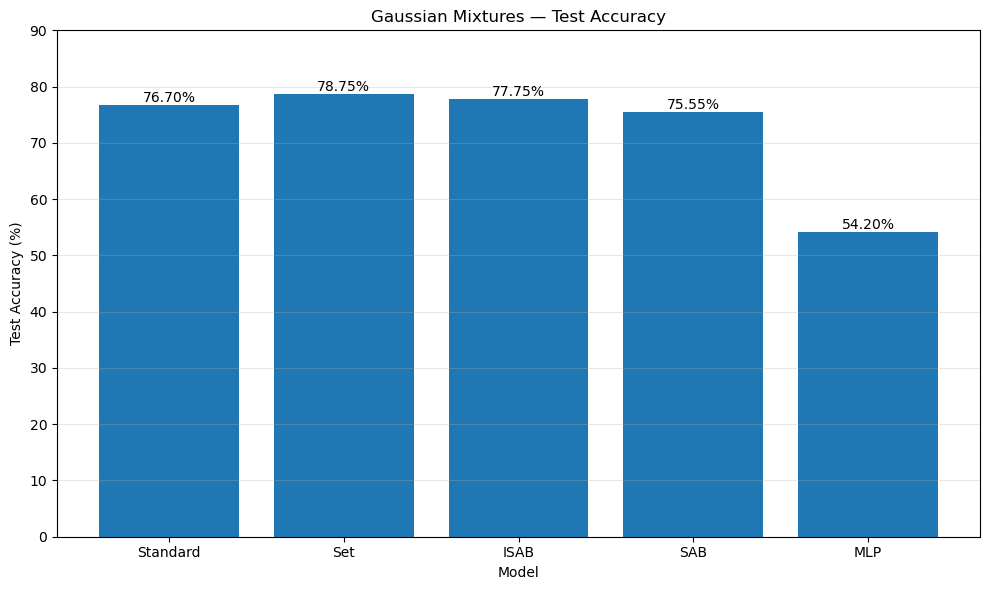

In [7]:
import matplotlib.pyplot as plt

models = ["Standard", "Set", "ISAB", "SAB", "MLP"]
accuracies = [76.70, 78.75, 77.75, 75.55, 54.20]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, accuracies)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.title("Gaussian Mixtures — Test Accuracy")
plt.ylim(0, 90)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("results/gaussian_test_accuracy.png", dpi=300)
plt.show()

In [9]:
import os
import sys
import subprocess
from pathlib import Path

# Locate torchvision on the HPC
result = subprocess.run(
    ["spack", "location", "-i", "py-torchvision@0.24.1"],
    capture_output=True,
    text=True
)

root = Path(result.stdout.strip())
site_packages = root / "lib" / "python3.13" / "site-packages"

sys.path.insert(0, str(site_packages))

# Pass the same Python paths to training subprocesses
env = os.environ.copy()
env["PYTHONPATH"] = os.pathsep.join(sys.path)

import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch: 2.9.1
Torchvision: 0.24.1
GPU: NVIDIA A100-PCIE-40GB
